# Modelo con TDA

Este notebook reutiliza las 16 características acústicas y las mismas pistas del modelo basal. Para cada pista, construye una nube con 13 MFCC por ventana, calcula homología persistente H0 y H1 mediante Vietoris–Rips y obtiene dos Persistence Images de 20 × 20. El vector aumentado tendrá 16 + 800 = 816 características.

Se conservan los géneros y las particiones oficiales de FMA. El conjunto `test` queda reservado para el notebook de comparación final.

In [1]:
import os
import time
from pathlib import Path

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from gtda.diagrams import PersistenceImage
from gtda.homology import VietorisRipsPersistence

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

## Datos del modelo basal

Se lee el CSV de características acústicas del primer notebook. Así se conservan los mismos IDs, géneros y splits. En este notebook se procesan `training` y `validation`; `test` permanece reservado.

In [17]:
# Carpeta del notebook y sus resultados.
PROJECT_DIR = Path.cwd()

# Datos del proyecto anterior.
METADATA_DIR = Path(os.environ.get("FMA_METADATA_DIR", str(PROJECT_DIR / "fma_metadata")))
AUDIO_DIR = Path(os.environ.get("FMA_AUDIO_DIR", str(PROJECT_DIR / "fma_medium")))

RESULTS_DIR = PROJECT_DIR / "resultados"
DIAGRAMS_DIR = RESULTS_DIR / "diagramas_tda"
DIAGRAMS_DIR.mkdir(parents=True, exist_ok=True)

FEATURES_FILE = RESULTS_DIR / "caracteristicas_basales.csv"
if not FEATURES_FILE.is_file():
    raise FileNotFoundError(FEATURES_FILE)
if not AUDIO_DIR.is_dir():
    raise FileNotFoundError(AUDIO_DIR)

# Mismos IDs, géneros y particiones que en el basal.
basal = pd.read_csv(FEATURES_FILE).set_index("track_id").sort_index()
basal = basal.loc[basal["split"].isin(["training", "validation"])].copy()

FEATURE_COLS = [f"mfcc_{i}" for i in range(13)] + [
    "centroid", "rolloff", "zcr"
]

basal[["genre", "split"]].value_counts()

genre          split     
Rock           training      5676
Electronic     training      5048
Experimental   training      1800
Hip-Hop        training      1752
Folk           training      1214
Instrumental   training      1044
Pop            training       945
International  training       814
Rock           validation     711
Electronic     validation     631
Experimental   validation     225
Hip-Hop        validation     220
Folk           validation     152
Instrumental   validation     131
Pop            validation     122
International  validation     102
Name: count, dtype: int64

In [3]:
#parametros 
#La nube usa los 13 MFCC de cada ventana Hamming, sin promediarlos. Se calculan H0 y H1 con coeficientes en Z2. Cada imagen tendrá 20 × 20 píxeles.

SR = 22050             # Muestras de audio por segundo.
DURATION = 30          # Segundos utilizados por pista.
N_FFT = 1024           # Tamaño de la ventana Hamming.
HOP_LENGTH = 512       # Avance entre ventanas.
N_MFCC = 13            # Dimensión de cada punto de la nube.

N_BINS = 20            # Píxeles por lado de cada Persistence Image.
SIGMAS = [0.5, 1.0, 2.0]
SEED = 42

RF_TREES = 100
RF_MAX_DEPTH = 20

XGB_TREES = 100
XGB_LEARNING_RATE = 0.1
XGB_MAX_DEPTH = 6

SVM_C = [0.1, 1, 10, 100]
SVM_GAMMA = ["scale", 0.001, 0.01]

In [4]:
# Nube de puntos por pista
#Se carga y normaliza el audio igual que en el basal. Cada ventana produce 13 MFCC yno se calcula su media temporal

def mfcc_cloud(track_id):
    filename = f"{track_id:06d}"
    audio_path = AUDIO_DIR / filename[:3] / f"{filename}.mp3"

    audio, _ = librosa.load(
        audio_path, sr=SR, mono=True, duration=DURATION
    )
    if len(audio) < N_FFT:
        raise ValueError(f"Audio demasiado corto: {audio_path}")

    audio = audio / max(np.max(np.abs(audio)), 1e-12)

    spectrum = np.abs(
        librosa.stft(
            audio, n_fft=N_FFT,
            hop_length=HOP_LENGTH,
            window="hamming"
        )
    )
    mel = librosa.feature.melspectrogram(S=spectrum**2, sr=SR)
    mfcc = librosa.feature.mfcc(
        S=librosa.power_to_db(mel), n_mfcc=N_MFCC
    )

    return mfcc.T

## Prueba de homología persistente

Primero se calcula el diagrama de una pista completa para ver si es viable temporalmente

In [5]:
rips = VietorisRipsPersistence(
    metric="euclidean",
    homology_dimensions=(0, 1),
    coeff=2,
    reduced_homology=True
)

track_id = int(basal.index[0])
cloud = mfcc_cloud(track_id)

start = time.perf_counter()
diagram = rips.fit_transform([cloud])[0]
elapsed = time.perf_counter() - start

np.save(DIAGRAMS_DIR / f"{track_id:06d}.npy", diagram)

print("Nube:", cloud.shape)
print("Diagrama:", diagram.shape)
print(f"Tiempo de una pista: {elapsed:.1f} s")



Nube: (1291, 13)
Diagrama: (2343, 3)
Tiempo de una pista: 0.7 s


In [6]:

#Diagramas H0 y H1

for i, track_id in enumerate(basal.index, start=1):
    path = DIAGRAMS_DIR / f"{track_id:06d}.npy"

    if not path.exists():
        cloud = mfcc_cloud(int(track_id))
        diagram = rips.fit_transform([cloud])[0]
        np.save(path, diagram)

    if i % 250 == 0 or i == len(basal):
        print(f"{i}/{len(basal)} pistas revisadas")

#Diagramas con tamaño uniforme
#Se rellenan con puntos de persistencia cero para poder procesar todos los diagramas como una sola matriz, los puntos reales no se modifican

diagrams = [
    np.load(DIAGRAMS_DIR / f"{track_id:06d}.npy")
    for track_id in basal.index
]

max_count = {
    dim: max(
        1,
        max(np.count_nonzero(d[:, 2] == dim) for d in diagrams)
    )
    for dim in (0, 1)
}

D = np.zeros(
    (len(diagrams), sum(max_count.values()), 3),
    dtype=np.float32
)

for i, diagram in enumerate(diagrams):
    start = 0

    for dim in (0, 1):
        count = max_count[dim]
        part = diagram[diagram[:, 2] == dim]

        D[i, start:start + count, 2] = dim
        D[i, start:start + len(part)] = part
        start += count

del diagrams

train_mask = basal["split"].eq("training").to_numpy()
val_mask = basal["split"].eq("validation").to_numpy()

D_train = D[train_mask]
D_val = D[val_mask]

X_spec = basal[FEATURE_COLS].to_numpy(dtype=np.float32)
X_spec_train = X_spec[train_mask]
X_spec_val = X_spec[val_mask]

y_train = basal.loc[train_mask, "genre"]
y_val = basal.loc[val_mask, "genre"]

250/20587 pistas revisadas
500/20587 pistas revisadas
750/20587 pistas revisadas
1000/20587 pistas revisadas
1250/20587 pistas revisadas
1500/20587 pistas revisadas
1750/20587 pistas revisadas
2000/20587 pistas revisadas
2250/20587 pistas revisadas
2500/20587 pistas revisadas
2750/20587 pistas revisadas
3000/20587 pistas revisadas
3250/20587 pistas revisadas
3500/20587 pistas revisadas
3750/20587 pistas revisadas
4000/20587 pistas revisadas
4250/20587 pistas revisadas
4500/20587 pistas revisadas
4750/20587 pistas revisadas
5000/20587 pistas revisadas
5250/20587 pistas revisadas
5500/20587 pistas revisadas
5750/20587 pistas revisadas
6000/20587 pistas revisadas
6250/20587 pistas revisadas
6500/20587 pistas revisadas
6750/20587 pistas revisadas
7000/20587 pistas revisadas
7250/20587 pistas revisadas
7500/20587 pistas revisadas
7750/20587 pistas revisadas
8000/20587 pistas revisadas
8250/20587 pistas revisadas
8500/20587 pistas revisadas
8750/20587 pistas revisadas
9000/20587 pistas revis

16750/20587 pistas revisadas


17000/20587 pistas revisadas


17250/20587 pistas revisadas


17500/20587 pistas revisadas


17750/20587 pistas revisadas


... (8 outputs left out)

20000/20587 pistas revisadas


20250/20587 pistas revisadas


20500/20587 pistas revisadas


20587/20587 pistas revisadas


## Vectorización topológica

Cada diagrama genera dos Persistence Images: una de H0 y otra de H1. Se aplica la ponderación por persistencia descrita en la metodología y se aplanan las imágenes para obtener 800 valores por pista.

In [7]:
def linear_weight(persistence):
    return persistence


def pi_features(pi, diagrams):
    images = pi.transform(diagrams)

    persistence = diagrams[:, :, 1] - diagrams[:, :, 0]

    for channel, dim in enumerate(pi.homology_dimensions_):
        maximum = np.where(
            diagrams[:, :, 2] == dim,
            persistence,
            0
        ).max(axis=1)

        images[:, channel] /= np.maximum(maximum, 1e-12)[:, None, None]

    return images.reshape(len(diagrams), -1)

In [9]:
# Compatibilidad de giotto-tda con NumPy 2.
if not hasattr(np, "product"):
    np.product = np.prod

In [10]:
# seleccion de sigma
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

sigma_results = []

for sigma in SIGMAS:
    fold_f1 = []

    for train_idx, fold_idx in cv.split(X_spec_train, y_train):
        pi = PersistenceImage(
            sigma=sigma,
            n_bins=N_BINS,
            weight_function=linear_weight
        )
        pi.fit(D_train[train_idx])

        X_fold_train = np.hstack([
            X_spec_train[train_idx],
            pi_features(pi, D_train[train_idx])
        ])
        X_fold_val = np.hstack([
            X_spec_train[fold_idx],
            pi_features(pi, D_train[fold_idx])
        ])

        rf = RandomForestClassifier(
            n_estimators=RF_TREES,
            max_depth=RF_MAX_DEPTH,
            criterion="gini",
            random_state=SEED
        )
        rf.fit(X_fold_train, y_train.iloc[train_idx])
        prediction = rf.predict(X_fold_val)

        fold_f1.append(
            f1_score(
                y_train.iloc[fold_idx],
                prediction,
                average="weighted"
            )
        )

    sigma_results.append({
        "sigma": sigma,
        "f1_ponderado_cv": np.mean(fold_f1)
    })

sigma_results = pd.DataFrame(sigma_results)
best_sigma = float(
    sigma_results.loc[
        sigma_results["f1_ponderado_cv"].idxmax(), "sigma"
    ]
)

display(sigma_results.round(4))
print("Sigma elegido:", best_sigma)

,sigma,f1_ponderado_cv
0,0.5,0.4982
1,1.0,0.4943
2,2.0,0.4845


Sigma elegido: 0.5


## Construcción del vector aumentado

La Persistence Image se ajusta exclusivamente con `training`. Se aplica después a ambas particiones. Cada fila resultante tiene 816 características.

In [11]:
pi = PersistenceImage(
    sigma=best_sigma,
    n_bins=N_BINS,
    weight_function=linear_weight
)
pi.fit(D_train)

X_pi_train = pi_features(pi, D_train)
X_pi_val = pi_features(pi, D_val)

X_train = np.hstack([X_spec_train, X_pi_train])
X_val = np.hstack([X_spec_val, X_pi_val])

assert X_train.shape[1] == 816
assert X_val.shape[1] == 816

np.savez_compressed(
    RESULTS_DIR / "tda_pi_train_validation.npz",
    track_ids=basal.index.to_numpy(),
    X_pi=pi_features(pi, D),
    sigma=best_sigma
)

X_train.shape, X_val.shape

((18293, 816), (2294, 816))

## Entrenamiento

Se entrenan Random Forest, SVM RBF y XGBoost con el vector aumentado. SVM escala los datos dentro de su Pipeline y selecciona C y gamma mediante validación cruzada.

In [12]:
scoring = {
    "accuracy": "accuracy",
    "f1_weighted": "f1_weighted"
}

rf = RandomForestClassifier(
    n_estimators=RF_TREES,
    max_depth=RF_MAX_DEPTH,
    criterion="gini",
    random_state=SEED
)
rf_cv = cross_validate(rf, X_train, y_train, cv=cv, scoring=scoring)
rf.fit(X_train, y_train)

svm = GridSearchCV(
    Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(kernel="rbf"))
    ]),
    {"svc__C": SVM_C, "svc__gamma": SVM_GAMMA},
    cv=cv,
    scoring="f1_weighted"
)
svm.fit(X_train, y_train)

encoder = LabelEncoder().fit(y_train)
y_train_encoded = encoder.transform(y_train)

xgb = XGBClassifier(
    n_estimators=XGB_TREES,
    learning_rate=XGB_LEARNING_RATE,
    max_depth=XGB_MAX_DEPTH,
    random_state=SEED
)
xgb_cv = cross_validate(
    xgb, X_train, y_train_encoded, cv=cv, scoring=scoring
)
xgb.fit(X_train, y_train_encoded)

print("RF, F1 CV:", rf_cv["test_f1_weighted"].mean())
print("SVM, mejor F1 CV:", svm.best_score_)
print("SVM, parámetros:", svm.best_params_)
print("XGBoost, F1 CV:", xgb_cv["test_f1_weighted"].mean())

RF, F1 CV: 0.4979868204764271
SVM, mejor F1 CV: 0.5316126952319795
SVM, parámetros: {'svc__C': 10, 'svc__gamma': 0.01}
XGBoost, F1 CV: 0.5453580563006725


,modelo,sigma,accuracy_validation,f1_ponderado_validation
0,Random Forest,0.5,0.5567,0.4998
1,SVM RBF,0.5,0.5702,0.5282
2,XGBoost,0.5,0.5767,0.5404


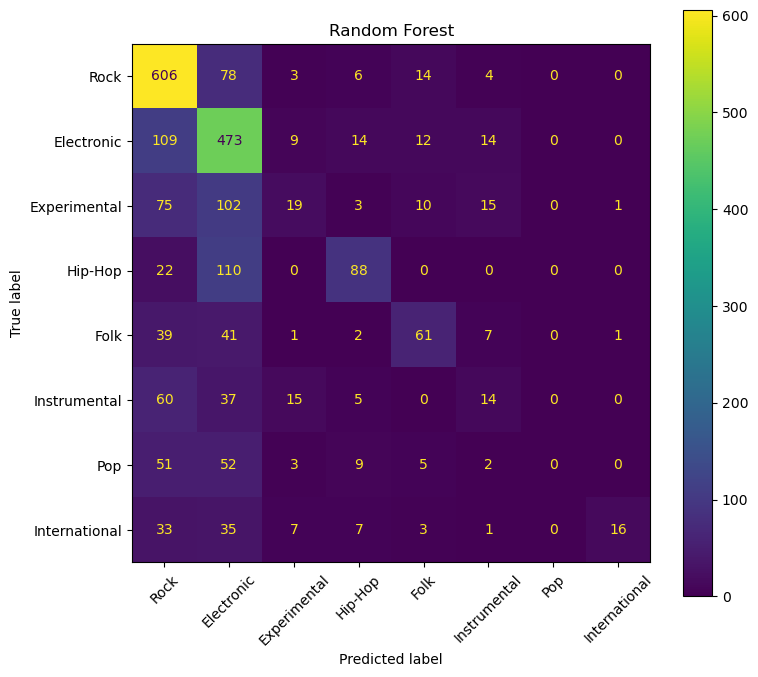

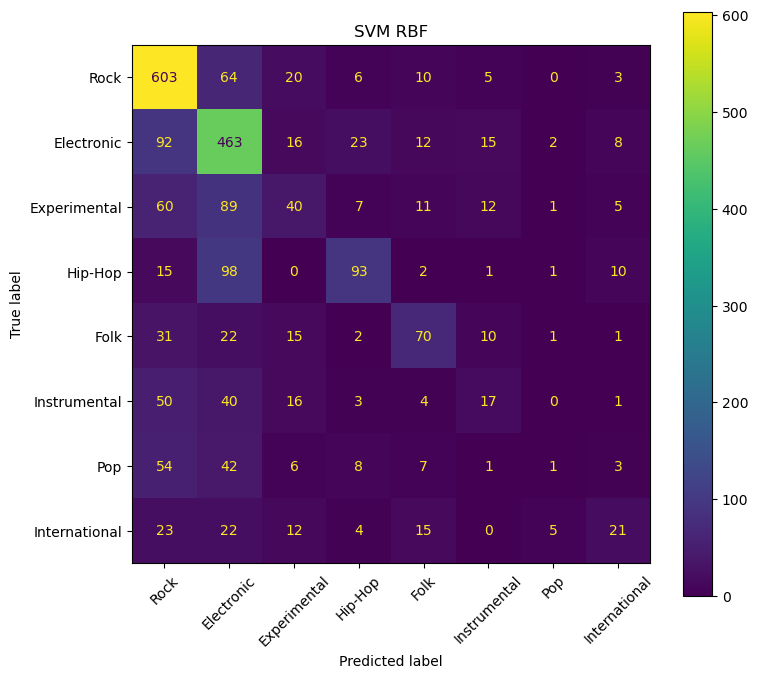

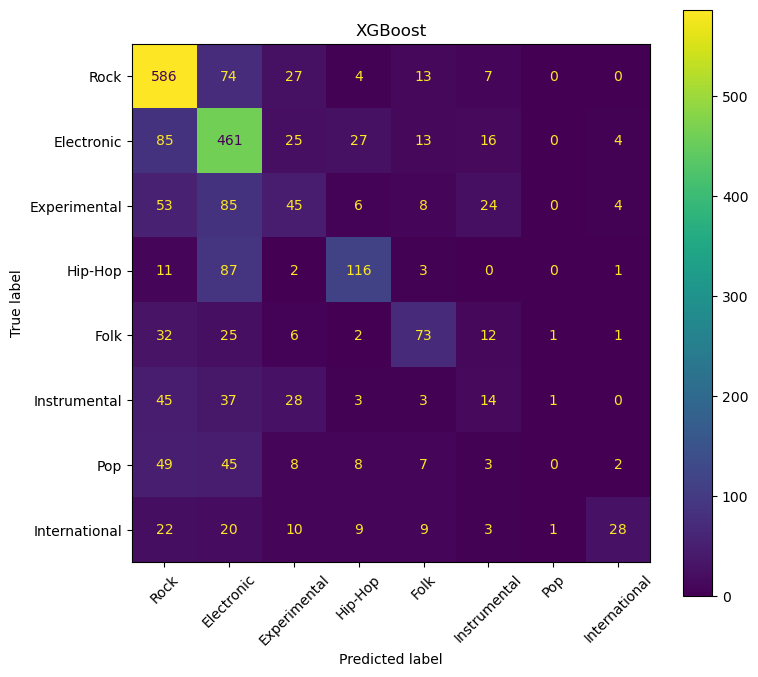

In [13]:
#Resultados de validación
#Se calculan accuracy, F1 ponderado y matrices de confusión sobre la partición oficial `validation`
#Estos resultados son preliminares y `test` sigue sin utilizarse

predictions = {
    "Random Forest": rf.predict(X_val),
    "SVM RBF": svm.predict(X_val),
    "XGBoost": encoder.inverse_transform(xgb.predict(X_val))
}

results = pd.DataFrame([
    {
        "modelo": name,
        "sigma": best_sigma,
        "accuracy_validation": accuracy_score(y_val, pred),
        "f1_ponderado_validation": f1_score(
            y_val, pred, average="weighted"
        )
    }
    for name, pred in predictions.items()
])

display(results.round(4))

prediction_table = pd.DataFrame({
    "track_id": basal.index[val_mask],
    "genre_real": y_val.to_numpy(),
    **predictions
})

results.to_csv(
    RESULTS_DIR / "tda_metricas_validation.csv", index=False
)
prediction_table.to_csv(
    RESULTS_DIR / "tda_predicciones_validation.csv", index=False
)

for name, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay.from_predictions(
        y_val,
        pred,
        labels=[
            "Rock", "Electronic", "Experimental", "Hip-Hop",
            "Folk", "Instrumental", "Pop", "International"
        ],
        xticks_rotation=45,
        values_format="d",
        ax=ax
    )
    ax.set_title(name)
    plt.tight_layout()
    plt.show()

## experimentación, configuraciones compartidas

Se prueban A, B, C y D, tal como en el basal. A cada vector acústico se le añaden las mismas 800 características topológicas H0/H1.

| Configuración | Atributos acústicos | Total con TDA | Pesos RF/SVM | Árboles RF/XGBoost |
|---|---:|---:|---|---:|
| A_original | 16 | 816 | No | 100 |
| B_atributos | 56 | 856 | No | 100 |
| C_pesos | 56 | 856 | Sí | 100 |
| D_arboles | 56 | 856 | Sí | 300 |

Se reutiliza el sigma elegido anteriormente. Las imágenes de persistencia se ajustan por separado en cada pliegue de `training`.

In [19]:
#cargar datos
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

SEED = 42
SVM_C = [0.1, 1, 10, 100]
SVM_GAMMA = ["scale", 0.001, 0.01]

base = pd.read_csv(
    RESULTS_DIR / "caracteristicas_basales.csv"
).set_index("track_id").sort_index()

acoustic_56 = pd.read_csv(
    RESULTS_DIR / "caracteristicas_acusticas_56.csv"
).set_index("track_id").sort_index()

with np.load(RESULTS_DIR / "tda_pi_train_validation.npz") as saved:
    sigma = float(saved["sigma"])

cols_16 = [f"mfcc_{i}" for i in range(13)] + [
    "centroid", "rolloff", "zcr"
]
cols_56 = cols_16 + (
    [f"mfcc_mean_{i}" for i in range(13, 20)]
    + [f"mfcc_std_{i}" for i in range(20)]
    + ["centroid_std"]
    + [f"chroma_mean_{i}" for i in range(12)]
)

if not base.index.equals(acoustic_56.index):
    raise ValueError("Los archivos acústicos no contienen los mismos track_id.")

train = base.loc[base["split"] == "training"]
ids = train.index
y = train["genre"].to_numpy()
y_encoded = LabelEncoder().fit_transform(y)

X16 = base.loc[ids, cols_16].to_numpy()
X56 = acoustic_56.loc[ids, cols_56].to_numpy()

if X16.shape[1] != 16 or X56.shape[1] != 56:
    raise ValueError("Se esperaban 16 y 56 atributos acústicos.")

diagrams = [
    np.load(RESULTS_DIR / "diagramas_tda" / f"{track_id:06d}.npy")
    for track_id in ids
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("Training:", len(ids), "| Sigma:", sigma)

Training: 18293 | Sigma: 0.5


In [20]:
# Preparar diagramas por pliegue
#Los diagramas de cada grupo se rellenan con puntos diagonales para darles una forma uniforme
#Esta función no calcula de nuevo la homología

#Rellenar diagramas
def pad_diagrams(items):
    n0 = max(sum(d[:, 2] == 0) for d in items)
    n1 = max(1, max(sum(d[:, 2] == 1) for d in items))

    padded = np.zeros((len(items), n0 + n1, 3), dtype=np.float32)
    padded[:, n0:, 2] = 1

    for i, diagram in enumerate(items):
        h0 = diagram[diagram[:, 2] == 0]
        h1 = diagram[diagram[:, 2] == 1]
        padded[i, :len(h0)] = h0
        padded[i, n0:n0 + len(h1)] = h1

    return padded

In [21]:
#Evaluar sobre los mismos cinco pliegues
#Cada configuración usa las mismas particiones. Se registran accuracy y F1 ponderado por pliegue 
#SVM prueba la misma grilla de `C` y `gamma` del basal


#validación cruzada
configurations = [
    ("A_original", 16, None, 100),
    ("B_atributos", 56, None, 100),
    ("C_pesos", 56, "balanced", 100),
    ("D_arboles", 56, "balanced", 300)
]

rows = []

def save_score(fold, config, model, actual, predicted, C="", gamma=""):
    rows.append({
        "fold": fold,
        "configuracion": config,
        "modelo": model,
        "C": str(C),
        "gamma": str(gamma),
        "accuracy": accuracy_score(actual, predicted),
        "f1_ponderado": f1_score(
            actual, predicted, average="weighted", zero_division=0
        )
    })

for fold, (fit_idx, val_idx) in enumerate(cv.split(X16, y), start=1):
    D_fit = pad_diagrams([diagrams[i] for i in fit_idx])
    D_val = pad_diagrams([diagrams[i] for i in val_idx])

    pi_fold = PersistenceImage(
        sigma=sigma,
        n_bins=20,
        weight_function=linear_weight
    )
    pi_fold.fit(D_fit)

    PI_fit = pi_features(pi_fold, D_fit)
    PI_val = pi_features(pi_fold, D_val)

    for config, n_features, weight, trees in configurations:
        acoustic = X16 if n_features == 16 else X56
        X_fit = np.hstack([acoustic[fit_idx], PI_fit])
        X_val = np.hstack([acoustic[val_idx], PI_val])

        forest = RandomForestClassifier(
            n_estimators=trees,
            max_depth=20,
            criterion="gini",
            class_weight=weight,
            random_state=SEED
        )
        forest.fit(X_fit, y[fit_idx])
        save_score(
            fold, config, "Random Forest",
            y[val_idx], forest.predict(X_val)
        )

        boost = XGBClassifier(
            n_estimators=trees,
            learning_rate=0.1,
            max_depth=6,
            random_state=SEED
        )
        boost.fit(X_fit, y_encoded[fit_idx])
        predicted = boost.predict(X_val)
        save_score(
            fold, config, "XGBoost",
            y_encoded[val_idx], predicted
        )

        for C in SVM_C:
            for gamma in SVM_GAMMA:
                svm = make_pipeline(
                    StandardScaler(),
                    SVC(
                        kernel="rbf",
                        C=C,
                        gamma=gamma,
                        class_weight=weight
                    )
                )
                svm.fit(X_fit, y[fit_idx])
                save_score(
                    fold, config, "SVM RBF",
                    y[val_idx], svm.predict(X_val),
                    C=C, gamma=gamma
                )

    pd.DataFrame(rows).to_csv(
        RESULTS_DIR / "tda_experimento_cv_folds.csv", index=False
    )
    print(f"Pliegue {fold}/5")

Pliegue 1/5


Pliegue 2/5


Pliegue 3/5


Pliegue 4/5


Pliegue 5/5


In [22]:
#Resumir los resultados
#Se promedian los cinco pliegues. Para SVM se conserva, en cada configuración, la combinación `C`/`gamma` con mayor F1 ponderado promedio.
#Aún no se elige una configuración general: primero se comparará esta tabla con la del basal.

fold_results = pd.DataFrame(rows)

means = fold_results.groupby(
    ["configuracion", "modelo", "C", "gamma"],
    as_index=False
)[["accuracy", "f1_ponderado"]].mean()

tda_experiment = (
    means.sort_values("f1_ponderado", ascending=False)
    .drop_duplicates(["configuracion", "modelo"])
    .sort_values(["configuracion", "modelo"])
    .rename(columns={
        "accuracy": "accuracy_cv",
        "f1_ponderado": "f1_cv"
    })
)

display(
    tda_experiment.pivot(
        index="configuracion", columns="modelo", values="f1_cv"
    ).round(4)
)

tda_experiment.to_csv(
    RESULTS_DIR / "tda_experimento_cv.csv", index=False
)

modelo,Random Forest,SVM RBF,XGBoost
configuracion,,,
A_original,0.4982,0.5320,0.5471
B_atributos,0.5401,0.5922,0.5921
C_pesos,0.5432,0.5886,0.5921
D_arboles,0.5496,0.5886,0.6030


## Otra prueba 

E usa 56 atributos acústicos, 800 topológicos, 300 árboles y ningún peso. Frente a B, solo cambia el número de árboles. Su SVM es idéntico al de B.

F mantiene los parámetros de E y reduce únicamente las 800 características topológicas a 100 componentes PCA. PCA se ajusta solo con las pistas de entrenamiento de cada pliegue. Se comparan accuracy y F1 ponderado.

In [23]:
from sklearn.decomposition import PCA

last_rows = []
explained_variance = []

def add_score(fold, config, model, actual, predicted, C="", gamma=""):
    last_rows.append({
        "fold": fold,
        "configuracion": config,
        "modelo": model,
        "C": str(C),
        "gamma": str(gamma),
        "accuracy": accuracy_score(actual, predicted),
        "f1_ponderado": f1_score(
            actual, predicted, average="weighted", zero_division=0
        )
    })

for fold, (fit_idx, val_idx) in enumerate(cv.split(X56, y), start=1):
    D_fit = pad_diagrams([diagrams[i] for i in fit_idx])
    D_val = pad_diagrams([diagrams[i] for i in val_idx])

    pi_fold = PersistenceImage(
        sigma=sigma,
        n_bins=20,
        weight_function=linear_weight
    )
    pi_fold.fit(D_fit)

    PI_fit = pi_features(pi_fold, D_fit)
    PI_val = pi_features(pi_fold, D_val)

    pca = PCA(
        n_components=100,
        svd_solver="randomized",
        random_state=SEED
    )
    PI_fit_100 = pca.fit_transform(PI_fit)
    PI_val_100 = pca.transform(PI_val)
    explained_variance.append(pca.explained_variance_ratio_.sum())

    variants = [
        ("E_sin_pesos_300", PI_fit, PI_val),
        ("F_pca_100", PI_fit_100, PI_val_100)
    ]

    for config, top_fit, top_val in variants:
        X_fit = np.hstack([X56[fit_idx], top_fit])
        X_val = np.hstack([X56[val_idx], top_val])

        forest = RandomForestClassifier(
            n_estimators=300,
            max_depth=20,
            criterion="gini",
            random_state=SEED
        )
        forest.fit(X_fit, y[fit_idx])
        add_score(
            fold, config, "Random Forest",
            y[val_idx], forest.predict(X_val)
        )

        boost = XGBClassifier(
            n_estimators=300,
            learning_rate=0.1,
            max_depth=6,
            random_state=SEED
        )
        boost.fit(X_fit, y_encoded[fit_idx])
        add_score(
            fold, config, "XGBoost",
            y_encoded[val_idx], boost.predict(X_val)
        )

        if config == "F_pca_100":
            for C in SVM_C:
                for gamma in SVM_GAMMA:
                    svm = make_pipeline(
                        StandardScaler(),
                        SVC(kernel="rbf", C=C, gamma=gamma)
                    )
                    svm.fit(X_fit, y[fit_idx])
                    add_score(
                        fold, config, "SVM RBF",
                        y[val_idx], svm.predict(X_val),
                        C=C, gamma=gamma
                    )

    pd.DataFrame(last_rows).to_csv(
        RESULTS_DIR / "tda_ultima_cv_folds.csv", index=False
    )
    print(f"Pliegue {fold}/5")

print("Varianza media conservada por PCA:", np.mean(explained_variance))

Pliegue 1/5


Pliegue 2/5


Pliegue 3/5


Pliegue 4/5


Pliegue 5/5
Varianza media conservada por PCA: 0.9999927381388977


In [24]:
new_means = pd.DataFrame(last_rows).groupby(
    ["configuracion", "modelo", "C", "gamma"],
    as_index=False
)[["accuracy", "f1_ponderado"]].mean()

new_summary = (
    new_means.sort_values("f1_ponderado", ascending=False)
    .drop_duplicates(["configuracion", "modelo"])
    .rename(columns={
        "accuracy": "accuracy_cv",
        "f1_ponderado": "f1_cv"
    })
)

previous = pd.read_csv(RESULTS_DIR / "tda_experimento_cv.csv")
previous = previous.loc[
    previous["configuracion"].isin(["B_atributos", "D_arboles"])
].copy()

svm_E = previous.loc[
    (previous["configuracion"] == "B_atributos")
    & (previous["modelo"] == "SVM RBF")
].copy()
svm_E["configuracion"] = "E_sin_pesos_300"

tda_last = pd.concat(
    [previous, new_summary, svm_E],
    ignore_index=True
).sort_values(["configuracion", "modelo"])

display(
    tda_last[
        ["configuracion", "modelo", "accuracy_cv", "f1_cv"]
    ].round(4)
)

tda_last.to_csv(RESULTS_DIR / "tda_ultima_cv.csv", index=False)

,configuracion,modelo,accuracy_cv,f1_cv
0,B_atributos,Random Forest,0.5878,0.5401
1,B_atributos,SVM RBF,0.6177,0.5922
2,B_atributos,XGBoost,0.6215,0.5921
3,D_arboles,Random Forest,0.5947,0.5496
4,D_arboles,SVM RBF,0.5804,0.5886
5,D_arboles,XGBoost,0.6305,0.6030
10,E_sin_pesos_300,Random Forest,0.5910,0.5425
11,E_sin_pesos_300,SVM RBF,0.6177,0.5922
6,E_sin_pesos_300,XGBoost,0.6305,0.6030
9,F_pca_100,Random Forest,0.5944,0.5472
